# K5 m=1.33 — Diagnostic species-subcluster ordination

**Purpose.** Display **all saved diagnostic species subclusters** on a **single common ordination**, with PC1–PC2, PC1–PC3 and PC2–PC3. This is a new notebook; it **does not refit** the K5 parent model or the five parent-specific K-means subcluster assignments.

**Faithful to upstream pipeline:** the original `NCA_Vegetation_FCM_K5_m1p33_Subclusters.ipynb` determines species columns from the contiguous block **after `Year` and before `total_cover`**, excluding surface classes and `_FG` fields. It row-closes species abundance and applies the square-root (Hellinger) transform. Here, one **global PCA** is fitted to that same transformation across all positive-species observations, so that distinct parent-specific subclusters share a valid coordinate system.

**Important:** this is species-composition ordination with existing subcluster labels overlaid; it is **not an ordination of subcluster likelihoods or fuzzy memberships**, and does not independently validate the clustering. Empty-species observations remain in the audit but have no defined Hellinger coordinates. Verify which years—including 2026—are actually present in the saved CSV.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from IPython.display import display

SUBCLUSTER_CSV = Path(
    r"C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters"
    r"\Subclusters\NCA_K5_species_subclusters_bestSilhouette_DIAGNOSTIC.csv"
)
OUTPUT_DIR = SUBCLUSTER_CSV.parent / "Figures" / "Ordination"
EXPORT = True
REQUIRE_2026 = False  # Set True if the input is expected to contain 2026 plots

PARENT_NAMES = {1:"PBG", 2:"ARTR", 3:"Non-ARTR shrub", 4:"Exotic forb", 5:"EAG"}
PARENT_COLORS = {1:"#0072B2", 2:"#009E73", 3:"#E69F00", 4:"#CC79A7", 5:"#D55E00"}
PARENT_MARKERS = {1:"o", 2:"s", 3:"^", 4:"D", 5:"P"}
SURFACE_COLUMNS = {"BAREGROUND", "BIOCRUST", "LITTER", "ROCK", "SHIT", "TRASH"}
STATE_LABELS = {
 "1.1":"AGCR", "1.2":"POSE", "1.3":"PBG", "1.4":"PSSP6", "1.5":"Mixed/multi",
 "2.1":"ARTR + AGCR/CHVI", "2.2":"ARTR + BRTE", "2.3":"ARTR + POSE", "2.4":"ARTR + EF",
 "3.1":"Mixed shrub", "3.2":"CHVI8", "3.3":"KRLA2", "3.4":"ATCO",
 "4.1":"BAPR5", "4.2":"SATR12", "4.3":"BRASS", "4.4":"LEPE2", "4.5":"SIAL2", "4.6":"CETE5",
 "5.1":"BRTE/ARTR", "5.2":"BRTE mono", "5.3":"BRTE + AGCR", "5.4":"BRTE + BRASS", "5.5":"BRTE + POSE"
}
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10, "axes.spines.top":False,
                     "axes.spines.right":False, "pdf.fonttype":42, "ps.fonttype":42})


## 1. Load and validate the saved hierarchy

The diagnostic assignment CSV is itself the original vegetation master with extra parent and subcluster metadata. We therefore **do not merge tables or assume matching row order**.

In [2]:
if not SUBCLUSTER_CSV.exists():
    raise FileNotFoundError(f"Update SUBCLUSTER_CSV to your saved diagnostic file: {SUBCLUSTER_CSV}")
raw = pd.read_csv(SUBCLUSTER_CSV, low_memory=False)
needed = {"Year", "total_cover", "parent_cluster_k5", "diagnostic_state_id", "species_total"}
missing = needed - set(raw.columns)
if missing:
    raise ValueError(f"Missing required fields: {sorted(missing)}")

# Preserve upstream species-column selection EXACTLY.
year_pos = raw.columns.get_loc("Year")
total_pos = raw.columns.get_loc("total_cover")
if not (year_pos < total_pos):
    raise ValueError("Upstream species block (Year ... total_cover) not found in the expected order.")
species_cols = [c for c in raw.columns[year_pos+1:total_pos]
                if c not in SURFACE_COLUMNS and not c.endswith("_FG")]
if len(species_cols) < 2:
    raise ValueError("Species block contains fewer than two columns; inspect input schema.")

raw["parent"] = pd.to_numeric(raw["parent_cluster_k5"], errors="raise").astype(int)
if not raw["parent"].isin(PARENT_NAMES).all():
    raise ValueError("Unexpected parent label(s).")
raw["state_id"] = raw["diagnostic_state_id"].astype("string")
years = pd.to_numeric(raw["Year"], errors="coerce")
if years.isna().any():
    raise ValueError("Missing or nonnumeric Year values.")
raw["Year"] = years.astype(int)
if REQUIRE_2026 and not (raw["Year"] == 2026).any():
    raise ValueError("2026 observations are absent from this saved subcluster file.")

assigned = raw["state_id"].notna()
if assigned.any():
    prefixes = raw.loc[assigned, "state_id"].str.split(".", regex=False).str[0].astype(int)
    if not np.array_equal(prefixes.to_numpy(), raw.loc[assigned, "parent"].to_numpy()):
        raise ValueError("Diagnostic state parent prefix conflicts with parent_cluster_k5.")

print(f"Input observations: {len(raw):,}; species fields: {len(species_cols):,}")
print("Observation years:")
display(raw.groupby("Year", dropna=False).agg(
    all_plots=("parent", "size"), assigned_states=("state_id", "count")
))
print(f"Distinct saved diagnostic states: {raw['state_id'].nunique()}")
if 2026 not in raw["Year"].values:
    print("NOTE: The saved file contains NO 2026 plots. They cannot appear without updated assignments.")


Input observations: 1,171; species fields: 67
Observation years:


C:\Users\scottfordham\AppData\Local\Temp\ipykernel_30848\1895003249.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw["parent"] = pd.to_numeric(raw["parent_cluster_k5"], errors="raise").astype(int)
C:\Users\scottfordham\AppData\Local\Temp\ipykernel_30848\1895003249.py:22: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw["state_id"] = raw["diagnostic_state_id"].astype("string")


,all_plots,assigned_states
Year,,
2016,365,365
2018,234,230
2025,118,118
2026,454,452


Distinct saved diagnostic states: 24


## 2. One shared species-composition PCA

For positive-species plots, let \(p_{ij}=x_{ij}/\sum_j x_{ij}\). Hellinger coordinates are \(h_{ij}=\sqrt{p_{ij}}\). PCA of \(H\) is equivalent to Euclidean ordination of Hellinger-transformed species composition. Missing species values are treated as zero, **matching the upstream subcluster notebook**; negative abundances are prohibited.

No synthetic pure-species vertices are added: with hundreds of species, that would introduce an excessive and visually uninformative set of reference points.

In [3]:
X = raw[species_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0).to_numpy(dtype=float)
if not np.isfinite(X).all() or (X < 0).any():
    raise ValueError("Nonfinite/negative species abundance after conversion.")
totals = X.sum(axis=1)
positive = totals > 0

# Check that the same species block reproduces the upstream species_total.
old_total = pd.to_numeric(raw["species_total"], errors="coerce").to_numpy(dtype=float)
if not np.allclose(totals, old_total, atol=1e-5, rtol=1e-6, equal_nan=False):
    bad = np.count_nonzero(~np.isclose(totals, old_total, atol=1e-5, rtol=1e-6))
    raise ValueError(f"{bad} rows disagree with saved species_total; species schema may have changed.")
if (assigned & ~positive).any():
    raise ValueError("Assigned subclusters on zero-species observations.")
if (~assigned & positive).any():
    print(f"WARNING: {int((~assigned & positive).sum())} positive-species plots have no saved subcluster label.")

H = np.sqrt(X[positive] / totals[positive, None])
n_components = min(5, H.shape[0], H.shape[1])
if n_components < 3:
    raise ValueError("At least three PCA dimensions are needed.")
ordination_pca = PCA(n_components=n_components, svd_solver="full")
scores = ordination_pca.fit_transform(H)
explained = ordination_pca.explained_variance_ratio_

plot_data = raw.loc[positive, ["Year", "parent", "state_id"]].copy().reset_index(drop=False)
plot_data.rename(columns={"index": "source_row"}, inplace=True)
for j in range(n_components):
    plot_data[f"PC{j+1}"] = scores[:, j]
plot_data["state_label"] = plot_data["state_id"].map(STATE_LABELS)
plot_data["state_label"] = plot_data["state_label"].fillna(plot_data["state_id"])
print(f"Ordinated positive-species plots: {len(plot_data):,}")
print(f"Zero-species plots omitted from geometry: {int((~positive).sum()):,}")
print("Explained variation:", ", ".join(f"PC{i+1} {v:.1%}" for i,v in enumerate(explained)))
display(plot_data.groupby(["parent", "state_id"], dropna=False).size().rename("n").reset_index())


Ordinated positive-species plots: 1,165
Zero-species plots omitted from geometry: 6
Explained variation: PC1 25.7%, PC2 10.4%, PC3 9.4%, PC4 7.8%, PC5 6.4%


,parent,state_id,n
0,1,1.1,74
1,1,1.2,106
2,1,1.3,23
3,1,1.4,16
4,1,1.5,26
5,2,2.1,12
6,2,2.2,49
7,2,2.3,58
8,2,2.4,27
9,3,3.1,45


## 3. Publication-style paired and complementary views

**Color = K5 parent; marker shape = parent; within-parent shade = diagnostic species subcluster.** All observations are shown on the same global species-PCA coordinates. Subcluster centers (black-edged symbols) summarize **observed scores**, not fitted K-means centroids. The legend contains subcluster ID, descriptive label and counts. Set `SHOW_LABELS=False` if this is too crowded.

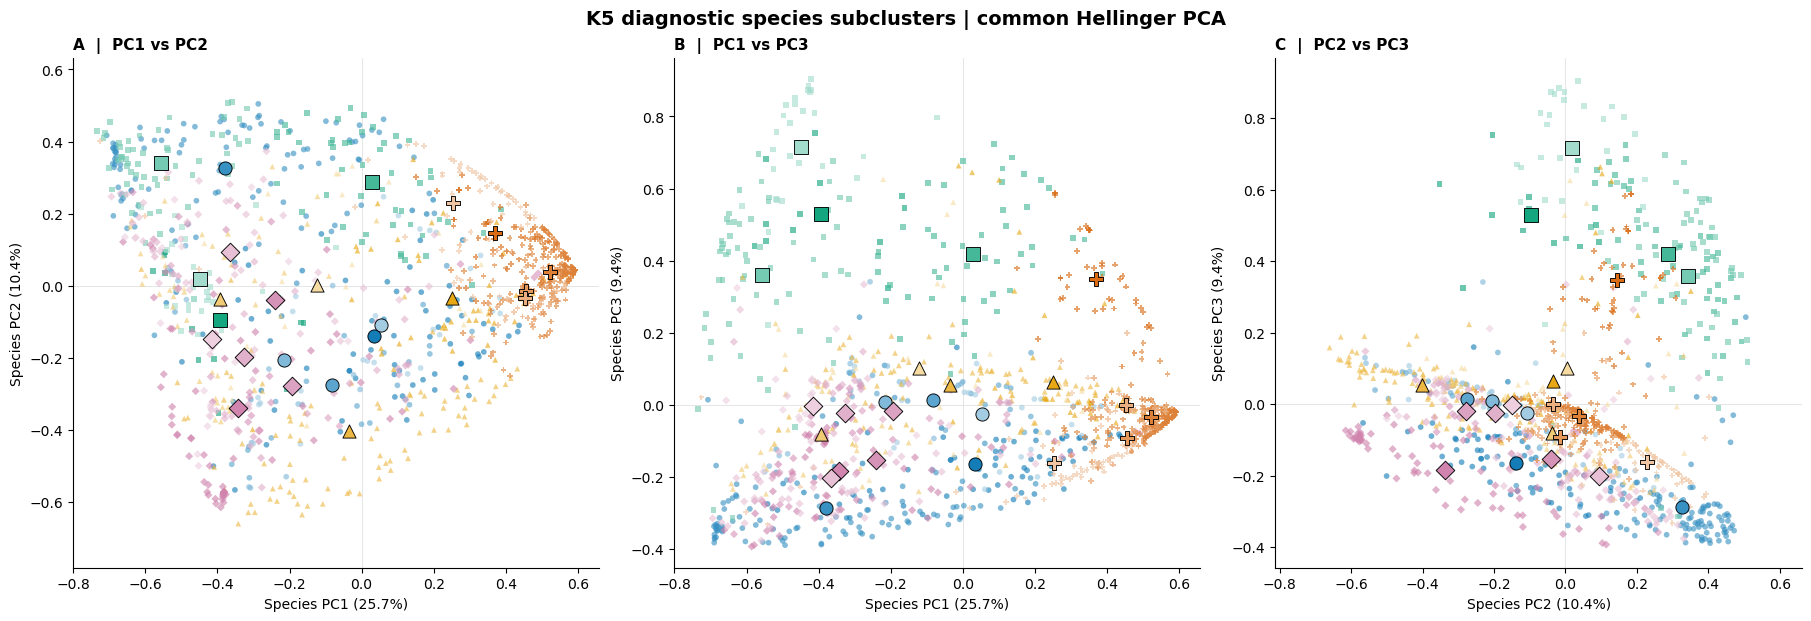

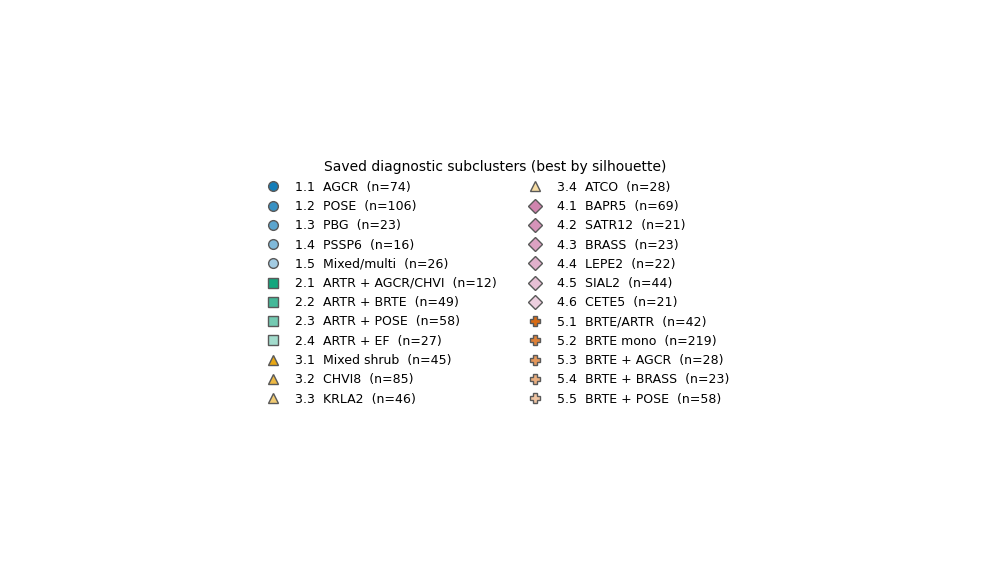

In [ ]:
def shade(hex_color, i, n):
    # Vary lightness within each parent while retaining parent hue.
    rgb = np.array(to_rgb(hex_color))
    t = 0.08 + (0.56 * i/max(n-1, 1))
    return tuple((1-t)*rgb + t*np.ones(3))

states = sorted(plot_data["state_id"].dropna().unique(),
                key=lambda s: tuple(map(int, s.split("."))))
state_color = {}
for parent in range(1, 6):
    children = [s for s in states if int(s.split(".")[0]) == parent]
    for i, s in enumerate(children):
        state_color[s] = shade(PARENT_COLORS[parent], i, len(children))

SHOW_LABELS = False  # subcluster-center labels inside axes; legend is always provided


def draw_panel(ax, px, py, *, show_labels=SHOW_LABELS):
    xcol, ycol = f"PC{px}", f"PC{py}"
    # Unassigned but positive-species observations (if any)
    unassigned = plot_data["state_id"].isna()
    if unassigned.any():
        ax.scatter(plot_data.loc[unassigned, xcol], plot_data.loc[unassigned, ycol],
                   s=12, color="0.75", alpha=.5, rasterized=True, zorder=1)
    for state in states:
        q = plot_data.loc[plot_data["state_id"].eq(state)]
        parent = int(state.split(".")[0])
        ax.scatter(q[xcol], q[ycol], s=17, marker=PARENT_MARKERS[parent],
                   color=state_color[state], alpha=.62, edgecolors="none",
                   rasterized=True, zorder=2)
        cx, cy = q[[xcol, ycol]].mean().to_numpy()
        ax.scatter(cx, cy, s=90, marker=PARENT_MARKERS[parent],
                   facecolor=state_color[state], edgecolor="black", linewidth=.65, zorder=4)
        if show_labels:
            ax.annotate(state, (cx, cy), xytext=(4, 4), textcoords="offset points",
                        fontsize=7, weight="semibold", color=PARENT_COLORS[parent])
    ax.axhline(0, color="0.88", lw=.6, zorder=0)
    ax.axvline(0, color="0.88", lw=.6, zorder=0)
    ax.set_xlabel(f"Species PC{px} ({explained[px-1]:.1%})")
    ax.set_ylabel(f"Species PC{py} ({explained[py-1]:.1%})")
    ax.set_aspect("equal", adjustable="datalim")

fig, axes = plt.subplots(1, 3, figsize=(18, 6.1), constrained_layout=True)
for ax, (px, py), letter in zip(axes, [(1,2), (1,3), (2,3)], "ABC"):
    draw_panel(ax, px, py)
    ax.set_title(f"{letter}  |  PC{px} vs PC{py}", loc="left", weight="bold", fontsize=11)
fig.suptitle("K5 diagnostic species subclusters | common Hellinger PCA", weight="bold", fontsize=14)
plt.show()

handles=[]
for state in states:
    parent=int(state.split(".")[0]); count=(plot_data["state_id"]==state).sum()
    handles.append(Line2D([], [], marker=PARENT_MARKERS[parent], linestyle="none", markersize=7,
                          markerfacecolor=state_color[state], markeredgecolor="0.35",
                          label=f"{state}  {STATE_LABELS.get(state,'')}  (n={count})"))
figlegend, axlegend=plt.subplots(figsize=(10, max(4.2, len(handles)*.24)))
axlegend.axis("off")
axlegend.legend(handles=handles, loc="center", frameon=False, ncol=2, fontsize=9,
                title="Saved diagnostic subclusters (best by silhouette)")
figlegend.tight_layout()
plt.show()



## 4. Optional faceted view: one K5 parent per panel

These plots **retain global coordinates and global PCA fit**, but isolate the subclusters within each parent. No panel refits PCA or rescales its biological basis.

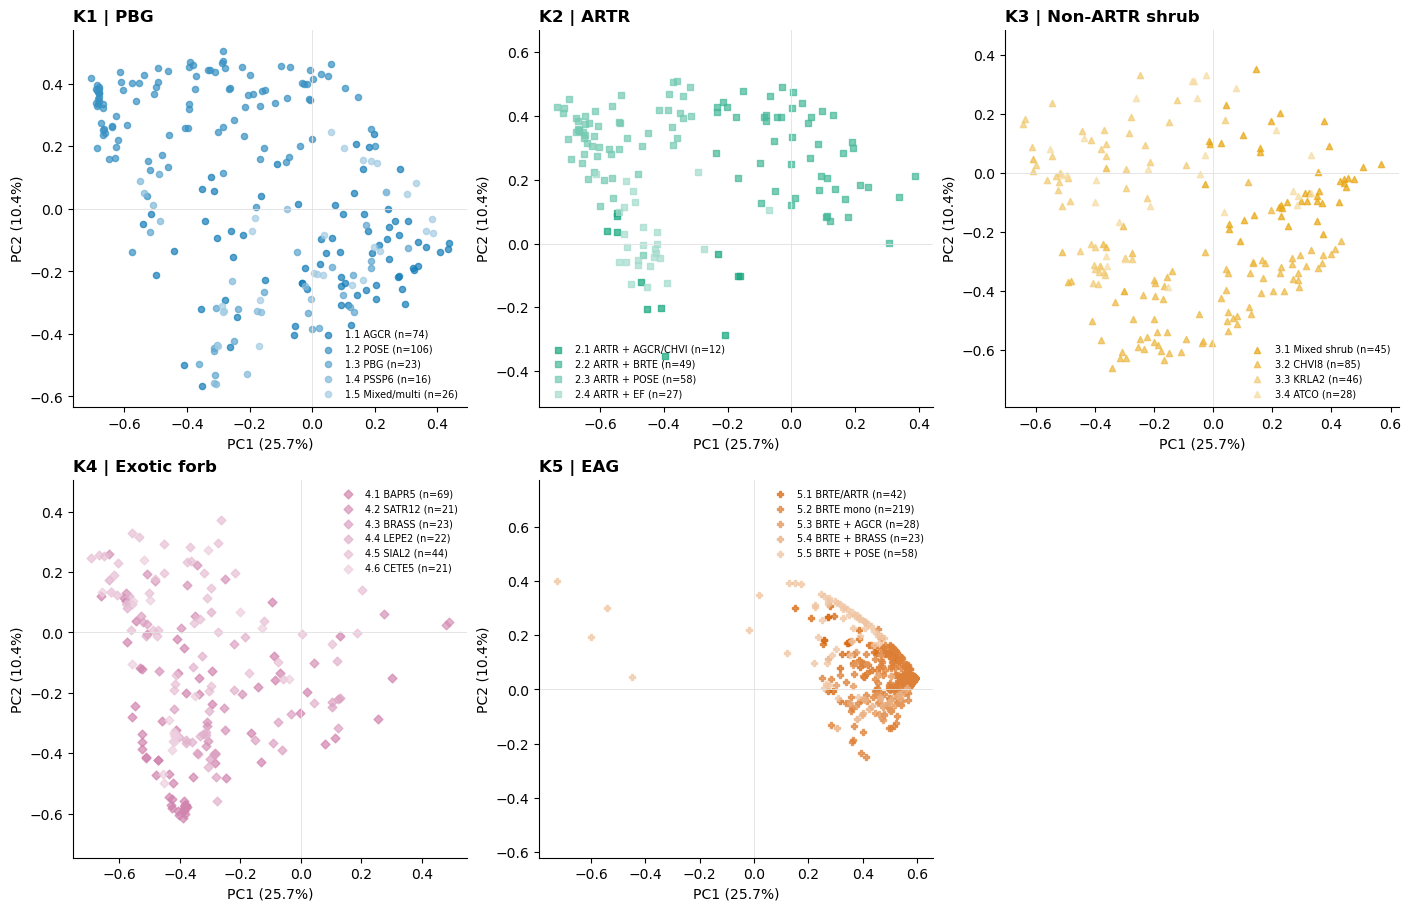

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for parent, ax in zip(range(1, 6), axs.flat):
    q_parent = plot_data.loc[plot_data["parent"] == parent]
    for state in [s for s in states if int(s.split(".")[0]) == parent]:
        q = q_parent[q_parent["state_id"] == state]
        ax.scatter(q.PC1, q.PC2, marker=PARENT_MARKERS[parent], s=20,
                   color=state_color[state], alpha=.7, rasterized=True,
                   label=f"{state} {STATE_LABELS.get(state, '')} (n={len(q)})")
    ax.set_title(f"K{parent} | {PARENT_NAMES[parent]}", loc="left", weight="bold")
    ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
    ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
    ax.legend(loc="best", fontsize=7, frameon=False)
    ax.axhline(0, color="0.88", lw=.6)
    ax.axvline(0, color="0.88", lw=.6)
    ax.set_aspect("equal", adjustable="datalim")
axs.flat[-1].axis("off")
plt.show()


## 5. Export and accounting

Export the global ordination, legend, faceted view, PCA loading matrix, and per-observation coordinates. Outputs are **not** generated unless you execute the notebook with `EXPORT=True`. The CSV includes `source_row` to map each point back to the input CSV.

In [6]:
audit = pd.DataFrame({
    "Year": raw["Year"], "parent_cluster_k5": raw["parent"],
    "diagnostic_state_id": raw["state_id"], "species_total_recomputed": totals,
    "included_in_ordination": positive,
    "reason": np.where(positive, "included", "zero_species_total")
})
print("AUDIT BY YEAR")
display(audit.groupby(["Year", "included_in_ordination"]).size().unstack(fill_value=0))
loadings = pd.DataFrame(ordination_pca.components_.T,
                        index=species_cols,
                        columns=[f"PC{i+1}" for i in range(n_components)])
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(OUTPUT_DIR / "K5_diagnostic_species_global_PCA_3panels.pdf", bbox_inches="tight")
    fig.savefig(OUTPUT_DIR / "K5_diagnostic_species_global_PCA_3panels.png", dpi=400, bbox_inches="tight")
    figlegend.savefig(OUTPUT_DIR / "K5_diagnostic_species_PCA_legend.pdf", bbox_inches="tight")
    plot_data.to_csv(OUTPUT_DIR / "K5_diagnostic_species_PCA_scores.csv", index=False)
    loadings.to_csv(OUTPUT_DIR / "K5_diagnostic_species_PCA_loadings.csv")
    audit.to_csv(OUTPUT_DIR / "K5_diagnostic_species_PCA_audit.csv", index=False)
    print("Saved to:", OUTPUT_DIR)


AUDIT BY YEAR


included_in_ordination,False,True
Year,,
2016,0,365
2018,4,230
2025,0,118
2026,2,452


Saved to: C:\NCA_DATA\Vegetation Data\Clustering_Veg\K5_m1p33_Subclusters\Subclusters\Figures\Ordination
